In [3]:
import os
import glob
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [4]:
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv
/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv


In [5]:
BASE_DIR = Path("/kaggle/working/ecommerce_project")

RAW_DIR = BASE_DIR / "raw"
PARQUET_DIR = BASE_DIR / "parquet"
OUTPUT_DIR = BASE_DIR / "outputs"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(BASE_DIR)

/kaggle/working/ecommerce_project


In [6]:
csv_files = glob.glob(
    "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/*.csv"
)

csv_files

['/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv',
 '/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv']

In [7]:
con = duckdb.connect(
    str(BASE_DIR/ "ecommerce.duckdb")
)

print(con.execute("SELECT version()").fetchone())

('v1.3.2',)


In [8]:
sample_file = csv_files[0]

sample = con.execute(f"""
        SELECT * 
        FROM read_csv_auto('{sample_file}')
        LIMIT 10
""").df()

sample

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-11-01 00:00:00,view,1003461,2053013555631882655,electronics.smartphone,xiaomi,489.07,520088904,4d3b30da-a5e4-49df-b1a8-ba5943f1dd33
1,2019-11-01 00:00:00,view,5000088,2053013566100866035,appliances.sewing_machine,janome,293.65,530496790,8e5f4f83-366c-4f70-860e-ca7417414283
2,2019-11-01 00:00:01,view,17302664,2053013553853497655,None,creed,28.31,561587266,755422e7-9040-477b-9bd2-6a6e8fd97387
3,2019-11-01 00:00:01,view,3601530,2053013563810775923,appliances.kitchen.washer,lg,712.87,518085591,3bfb58cd-7892-48cc-8020-2f17e6de6e7f
4,2019-11-01 00:00:01,view,1004775,2053013555631882655,electronics.smartphone,xiaomi,183.27,558856683,313628f1-68b8-460d-84f6-cec7a8796ef2
5,2019-11-01 00:00:01,view,1306894,2053013558920217191,computers.notebook,hp,360.09,520772685,816a59f3-f5ae-4ccd-9b23-82aa8c23d33c
6,2019-11-01 00:00:01,view,1306421,2053013558920217191,computers.notebook,hp,514.56,514028527,df8184cc-3694-4549-8c8c-6b5171877376
7,2019-11-01 00:00:02,view,15900065,2053013558190408249,None,rondell,30.86,518574284,5e6ef132-4d7c-4730-8c7f-85aa4082588f
8,2019-11-01 00:00:02,view,12708937,2053013553559896355,None,michelin,72.72,532364121,0a899268-31eb-46de-898d-09b2da950b24
9,2019-11-01 00:00:02,view,1004258,2053013555631882655,electronics.smartphone,apple,732.07,532647354,d2d3d2c6-631d-489e-9fb5-06f340b85be0


In [9]:
schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{sample_file}')
""").df()

schema

,column_name,column_type,null,key,default,extra
0,event_time,TIMESTAMP,YES,None,None,None
1,event_type,VARCHAR,YES,None,None,None
2,product_id,BIGINT,YES,None,None,None
3,category_id,BIGINT,YES,None,None,None
4,category_code,VARCHAR,YES,None,None,None
5,brand,VARCHAR,YES,None,None,None
6,price,DOUBLE,YES,None,None,None
7,user_id,BIGINT,YES,None,None,None
8,user_session,VARCHAR,YES,None,None,None


In [11]:
for file in csv_files:
    
    result = con.execute(f"""
        SELECT COUNT(*) AS row_count
        FROM read_csv_auto('{file}')
    """).fetchone()[0]
    
    print(
        Path(file).name,
        f"{result:,} rows"
    )

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019-Nov.csv 67,501,979 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019-Oct.csv 42,448,764 rows


In [12]:
event_counts = con.execute(f"""
    select
        event_type,
        count(*) as events
    from read_csv_auto('{sample_file}')
    group by event_type
    order by events DESC
""").df()

event_counts

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,events
0,view,63556110
1,cart,3028930
2,purchase,916939


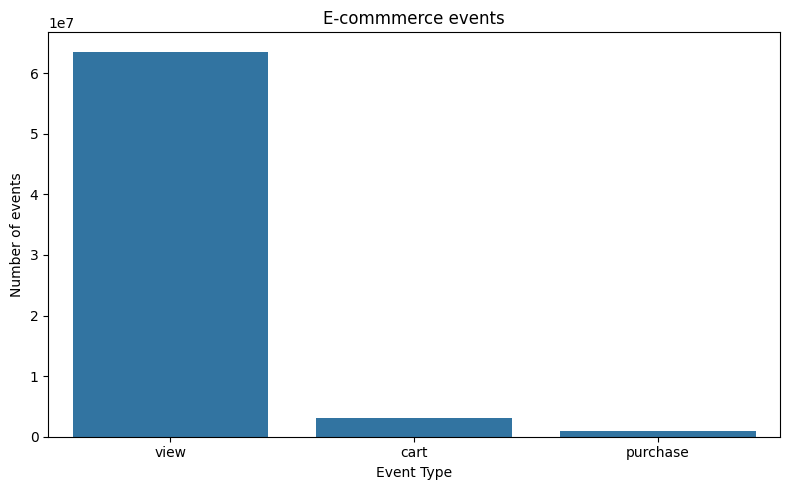

In [14]:
plt.figure(figsize=(8,5))

sns.barplot(
    data = event_counts,
    x = "event_type",
    y = "events"
)

plt.title("E-commmerce events")
plt.xlabel("Event Type")
plt.ylabel("Number of events")

plt.tight_layout()
plt.show()

In [16]:
quality = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE event_time IS NULL
        ) AS missing_event_time,

        COUNT(*) FILTER (
            WHERE event_type IS NULL
        ) AS missing_event_type,

        COUNT(*) FILTER (
            WHERE product_id IS NULL
        ) AS missing_product_id,

        COUNT(*) FILTER (
            WHERE category_id IS NULL
        ) AS missing_category_id,

        COUNT(*) FILTER (
            WHERE category_code IS NULL
        ) AS missing_category_code,

        COUNT(*) FILTER (
            WHERE brand IS NULL
        ) AS missing_brand,

        COUNT(*) FILTER (
            WHERE price IS NULL
        ) AS missing_price,

        COUNT(*) FILTER (
            WHERE user_id IS NULL
        ) AS missing_user_id,

        COUNT(*) FILTER (
            WHERE user_session IS NULL
        ) AS missing_session

    FROM read_csv_auto('{sample_file}')
""").df()

quality

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,missing_event_time,missing_event_type,missing_product_id,missing_category_id,missing_category_code,missing_brand,missing_price,missing_user_id,missing_session
0,67501979,0,0,0,0,21898171,9218235,0,0,10


In [18]:
con.execute(f"""
    SELECT DISTINCT event_type
    FROM read_csv_auto('{sample_file}')
    ORDER BY event_type
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type
0,cart
1,purchase
2,view


In [21]:
con.execute(f"""
    SELECT
        MIN(price) AS min_price,
        MAX(price) AS max_price,
        AVG(price) AS avg_price,
        MEDIAN(price) AS median_price
    FROM read_csv_auto('{sample_file}')
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_price,max_price,avg_price,median_price
0,0.0,2574.07,292.459317,165.77


In [23]:
file_pattern = (
    "/kaggle/input/datasets/mkechinov/"
    "ecommerce-behavior-data-from-multi-category-store/"
    "*.csv"
)

con.execute(f"""
    CREATE OR REPLACE VIEW raw_events AS
    SELECT *
    FROM read_csv_auto(
        '{file_pattern}',
        union_by_name = true
    )
""")

In [24]:
con.execute("""
    SELECT COUNT(*) AS total_events
    FROM raw_events
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events
0,109950743
